# Notebook 04 — Modelo de Machine Learning: Random Forest

## Modelagem de ciclos de atividade solar (Yearly Sunspot Numbers)

Este notebook constrói um modelo **Random Forest Regressor** para prever o número anual de manchas solares. O objetivo é compará-lo posteriormente ao ARIMA do Notebook 03, usando o mesmo intervalo de teste e o mesmo protocolo de previsão.

**Estratégia adotada:**
- série anual do conjunto `sunspots` do Statsmodels;
- últimos 40 anos reservados para teste (1969–2008);
- 12 defasagens (`t-1` a `t-12`) como variáveis de entrada;
- seleção de hiperparâmetros somente no período de treinamento, com validação cruzada temporal;
- previsão de um ano à frente com janela de treino expansiva: em cada ano, o modelo é reajustado e recebe apenas observações que já seriam conhecidas.

> Importante: as observações reais de cada ano do teste só entram no histórico **depois** que a previsão daquele ano é produzida. Isso evita utilizar o futuro para prever o passado.

## 1. Preparação do ambiente

Se alguma biblioteca não estiver instalada, execute no terminal ou em uma célula: `python -m pip install pandas numpy matplotlib statsmodels scikit-learn jupyter`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.datasets import sunspots
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

SEMENTE = 42
N_LAGS = 12
N_ANOS_TESTE = 40
np.random.seed(SEMENTE)

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Carregamento da série e separação cronológica

Usamos a mesma fonte do Notebook 03. A separação é cronológica: não embaralhamos os anos. O bloco final de 40 observações permanece reservado para a avaliação.

In [2]:
dados = sunspots.load_pandas().data.copy()
dados = dados.rename(columns={"YEAR": "ano", "SUNACTIVITY": "manchas"})
dados["ano"] = dados["ano"].astype(int)
dados["manchas"] = dados["manchas"].astype(float)
dados = dados.sort_values("ano").reset_index(drop=True)

serie = dados.set_index("ano")["manchas"]

if serie.isna().any():
    raise ValueError("A série contém valores ausentes. Trate-os antes de criar as defasagens.")
if not serie.index.is_monotonic_increasing or serie.index.has_duplicates:
    raise ValueError("O índice temporal precisa estar ordenado e sem anos duplicados.")
if len(serie) <= N_ANOS_TESTE + N_LAGS:
    raise ValueError("A série é curta demais para a divisão e o número de defasagens definidos.")

treino = serie.iloc[:-N_ANOS_TESTE].copy()
teste = serie.iloc[-N_ANOS_TESTE:].copy()

print(f"Série completa: {serie.index.min()}–{serie.index.max()} ({len(serie)} anos)")
print(f"Treino: {treino.index.min()}–{treino.index.max()} ({len(treino)} anos)")
print(f"Teste:  {teste.index.min()}–{teste.index.max()} ({len(teste)} anos)")
print(f"Número de defasagens: {N_LAGS}")
display(dados.head())
display(dados.tail())

Série completa: 1700–2008 (309 anos)
Treino: 1700–1968 (269 anos)
Teste:  1969–2008 (40 anos)
Número de defasagens: 12


,ano,manchas
0,1700,5.0
1,1701,11.0
2,1702,16.0
3,1703,23.0
4,1704,36.0


,ano,manchas
304,2004,40.4
305,2005,29.8
306,2006,15.2
307,2007,7.5
308,2008,2.9


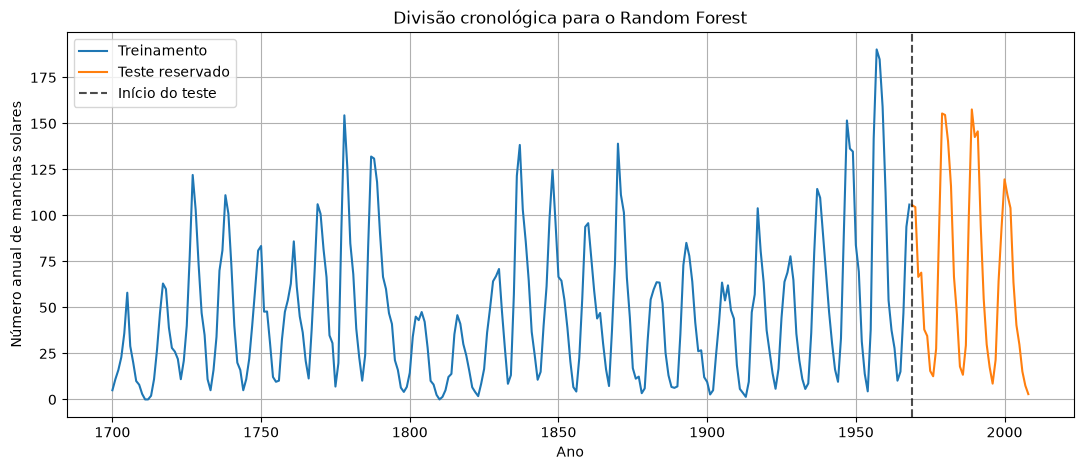

In [3]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(treino.index, treino.values, label="Treinamento")
ax.plot(teste.index, teste.values, label="Teste reservado")
ax.axvline(teste.index.min(), color="black", linestyle="--", alpha=0.7, label="Início do teste")
ax.set(title="Divisão cronológica para o Random Forest", xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.show()

## 3. Transformação da série em um problema supervisionado

O Random Forest do scikit-learn recebe uma matriz de características `X` e um vetor-alvo `y`. Para transformar a série temporal nesse formato, criaremos uma linha para cada ano-alvo:

\[
X_t = [y_{t-1}, y_{t-2}, \ldots, y_{t-12}], \qquad alvo = y_t
\]

Ou seja, a previsão para um ano usa somente os 12 valores anuais anteriores. Não incluímos o ano como variável porque o objetivo é testar o quanto o histórico recente ajuda a explicar a atividade solar.

In [4]:
def criar_dados_supervisionados(valores, n_lags=12):
    """Cria X com n_lags anteriores e y com o valor do ano-alvo."""
    valores = np.asarray(valores, dtype=float)
    if valores.ndim != 1:
        raise ValueError("A entrada precisa ser uma série unidimensional.")
    if len(valores) <= n_lags:
        raise ValueError("Há poucas observações para o número de defasagens.")

    X, y = [], []
    for posicao_alvo in range(n_lags, len(valores)):
        X.append(valores[posicao_alvo - n_lags:posicao_alvo][::-1])
        y.append(valores[posicao_alvo])

    nomes = [f"t-{lag}" for lag in range(1, n_lags + 1)]
    return pd.DataFrame(X, columns=nomes), np.asarray(y, dtype=float)

X_treino, y_treino = criar_dados_supervisionados(treino.values, N_LAGS)
anos_alvo_treino = treino.index[N_LAGS:]

print("Formato de X:", X_treino.shape)
print("Formato de y:", y_treino.shape)
print("Primeira linha de características — ano-alvo:", int(anos_alvo_treino[0]))
display(X_treino.head())
display(pd.DataFrame({"ano_alvo": anos_alvo_treino[:5], "manchas_alvo": y_treino[:5]}))

Formato de X: (257, 12)
Formato de y: (257,)
Primeira linha de características — ano-alvo: 1712


,t-1,t-2,t-3,t-4,t-5,t-6,t-7,t-8,t-9,t-10,t-11,t-12
0,0.0,3.0,8.0,10.0,20.0,29.0,58.0,36.0,23.0,16.0,11.0,5.0
1,0.0,0.0,3.0,8.0,10.0,20.0,29.0,58.0,36.0,23.0,16.0,11.0
2,2.0,0.0,0.0,3.0,8.0,10.0,20.0,29.0,58.0,36.0,23.0,16.0
3,11.0,2.0,0.0,0.0,3.0,8.0,10.0,20.0,29.0,58.0,36.0,23.0
4,27.0,11.0,2.0,0.0,0.0,3.0,8.0,10.0,20.0,29.0,58.0,36.0


,ano_alvo,manchas_alvo
0,1712,0.0
1,1713,2.0
2,1714,11.0
3,1715,27.0
4,1716,47.0


### Interpretação das colunas

- `t-1`: valor observado no ano imediatamente anterior ao alvo.
- `t-2`: valor observado dois anos antes.
- ...
- `t-12`: valor observado doze anos antes.

O primeiro alvo do treinamento só pode ser montado depois de existirem 12 observações anteriores. Por isso, a tabela supervisionada tem 12 linhas a menos que a série de treinamento.

## 4. Validação temporal e seleção de hiperparâmetros

O Random Forest possui escolhas que afetam a complexidade das árvores, como `max_depth`, `min_samples_leaf` e `max_features`. Vamos comparar combinações por validação cruzada temporal (`TimeSeriesSplit`) e minimizar o erro absoluto médio (MAE).

**Por que não usar validação aleatória?** Em séries temporais, embaralhar as linhas pode fazer o modelo ser validado em anos anteriores aos usados no ajuste, o que não representa a situação real de previsão. A validação temporal mantém a ordem dos exemplos.

A busca abaixo utiliza apenas exemplos derivados do período de treinamento; os anos de teste não participam da seleção.

In [5]:
divisor_temporal = TimeSeriesSplit(n_splits=4)

modelo_base = RandomForestRegressor(
    n_estimators=200,
    random_state=SEMENTE,
    n_jobs=-1
)

parametros = {
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 3],
    "max_features": [0.7, 1.0],
}

busca_rf = GridSearchCV(
    estimator=modelo_base,
    param_grid=parametros,
    scoring="neg_mean_absolute_error",
    cv=divisor_temporal,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise",
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    busca_rf.fit(X_treino, y_treino)

tabela_busca_rf = pd.DataFrame(busca_rf.cv_results_)
tabela_busca_rf = tabela_busca_rf[[
    "rank_test_score", "mean_test_score", "std_test_score",
    "mean_train_score", "params"
]].sort_values("rank_test_score").reset_index(drop=True)
tabela_busca_rf["MAE_validacao"] = -tabela_busca_rf["mean_test_score"]
tabela_busca_rf["MAE_treino"] = -tabela_busca_rf["mean_train_score"]

print("Melhores hiperparâmetros:", busca_rf.best_params_)
print(f"MAE médio da validação temporal: {-busca_rf.best_score_:.3f}")
display(tabela_busca_rf[["rank_test_score", "MAE_validacao", "MAE_treino", "std_test_score", "params"]].round(3))

Melhores hiperparâmetros: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}
MAE médio da validação temporal: 14.638


,rank_test_score,MAE_validacao,MAE_treino,std_test_score,params
0,1,14.638,4.107,4.512,"{'max_depth': None, 'max_features': 1.0, 'min_..."
1,2,14.700,4.116,4.472,"{'max_depth': 10, 'max_features': 1.0, 'min_sa..."
2,3,14.848,4.233,4.654,"{'max_depth': 10, 'max_features': 0.7, 'min_sa..."
3,4,14.901,4.211,4.653,"{'max_depth': None, 'max_features': 0.7, 'min_..."
4,5,14.958,6.000,5.096,"{'max_depth': 10, 'max_features': 1.0, 'min_sa..."
5,6,14.960,5.999,5.096,"{'max_depth': None, 'max_features': 1.0, 'min_..."
6,7,15.271,6.298,5.144,"{'max_depth': None, 'max_features': 0.7, 'min_..."
7,8,15.275,6.303,5.138,"{'max_depth': 10, 'max_features': 0.7, 'min_sa..."


### O que significa o resultado da busca?

A busca não mede o desempenho final no período de teste. Ela estima, dentro do bloco de treinamento, como cada configuração se comporta em divisões temporais sucessivas. O conjunto de teste continua reservado para a avaliação final.

A diferença entre `MAE_treino` e `MAE_validacao` também merece atenção: um erro muito menor no treino pode sinalizar sobreajuste (overfitting).

In [6]:
melhores_parametros = busca_rf.best_params_
melhor_mae_cv = -float(busca_rf.best_score_)

rf_selecionado = RandomForestRegressor(
    n_estimators=200,
    random_state=SEMENTE,
    n_jobs=-1,
    **melhores_parametros
)

print("Configuração selecionada para a avaliação:")
print(rf_selecionado)

Configuração selecionada para a avaliação:
RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)


## 5. Previsões de um passo à frente com janela expansiva

A avaliação seguirá o mesmo princípio usado no ARIMA:

1. treinar inicialmente com todos os exemplos supervisionados disponíveis até 1968;
2. prever 1969 usando os 12 valores anteriores;
3. somente depois da previsão, incorporar o valor real de 1969 ao histórico;
4. reajustar o Random Forest com todo o histórico disponível e prever 1970;
5. repetir até 2008.

Assim, cada previsão depende apenas de informações que estariam disponíveis naquele momento. O histórico expande a cada ano.

In [7]:
historico = treino.to_numpy(dtype=float).copy()
previsoes_rf = []

for ano, valor_real in teste.items():
    X_hist, y_hist = criar_dados_supervisionados(historico, N_LAGS)
    linha_previsao = pd.DataFrame(
        [historico[-N_LAGS:][::-1]],
        columns=[f"t-{lag}" for lag in range(1, N_LAGS + 1)]
    )

    modelo_atual = RandomForestRegressor(
        n_estimators=200,
        random_state=SEMENTE,
        n_jobs=-1,
        **melhores_parametros
    )
    modelo_atual.fit(X_hist, y_hist)
    previsao = float(modelo_atual.predict(linha_previsao)[0])
    previsoes_rf.append(previsao)

    # O dado real só é acrescentado depois de registrar a previsão do ano corrente.
    historico = np.append(historico, float(valor_real))

resultado_rf = pd.DataFrame({
    "real": teste.to_numpy(dtype=float),
    "previsao_rf": previsoes_rf,
}, index=teste.index)
resultado_rf.index.name = "ano"

print("Previsões produzidas:", len(resultado_rf))
display(resultado_rf.head(12).round(2))

Previsões produzidas: 40


,real,previsao_rf
ano,,
1969,105.5,115.13
1970,104.5,92.84
1971,66.6,74.29
1972,68.9,51.21
1973,38.0,50.62
1974,34.5,23.01
1975,15.5,27.73
1976,12.6,17.63
1977,27.5,24.31


## 6. Métricas de avaliação

Usaremos as mesmas métricas do Notebook 03:

- **MAE:** erro absoluto médio, na unidade original da série;
- **RMSE:** penaliza mais fortemente erros grandes;
- **MAPE:** erro percentual absoluto médio;
- **R²:** proporção da variação do alvo explicada em relação à média do período de teste.

O MAPE pode se tornar instável quando os valores reais são próximos de zero e é indefinido quando são exatamente zero. O código informa quantos pontos entram no cálculo, excluindo apenas valores reais exatamente iguais (ou numericamente muito próximos) de zero.

In [8]:
def calcular_metricas(y_real, y_previsto):
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)
    mascara_mape = np.abs(y_real) > 1e-8
    mape = (
        mean_absolute_percentage_error(y_real[mascara_mape], y_previsto[mascara_mape]) * 100
        if mascara_mape.any() else np.nan
    )
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "MAPE (%)": mape,
        "Pontos no MAPE": int(mascara_mape.sum()),
        "R²": r2_score(y_real, y_previsto),
    }

metricas_rf = pd.DataFrame({
    "Random Forest": calcular_metricas(resultado_rf["real"], resultado_rf["previsao_rf"])
}).T

display(metricas_rf.round(3))

,MAE,RMSE,MAPE (%),Pontos no MAPE,R²
Random Forest,12.726,16.795,45.76,40.0,0.879


## 7. Gráfico: valores reais e previsões

O gráfico permite verificar se o modelo acompanha os movimentos da série. Observe especialmente se ele identifica as subidas, os picos, as quedas e os períodos de baixa atividade.

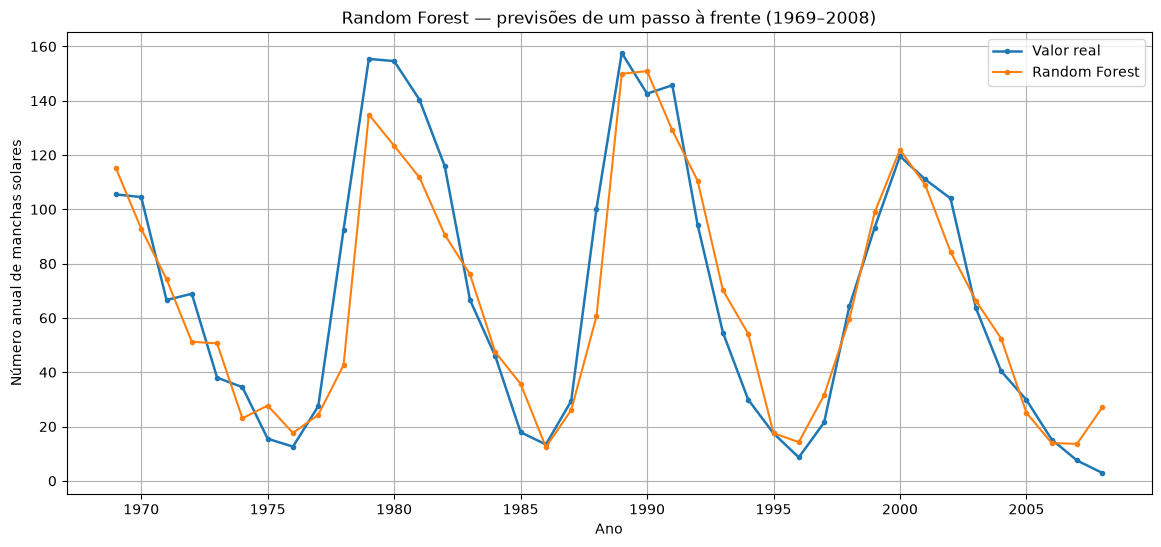

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(resultado_rf.index, resultado_rf["real"], marker="o", markersize=3, linewidth=1.8, label="Valor real")
ax.plot(resultado_rf.index, resultado_rf["previsao_rf"], marker="o", markersize=3, linewidth=1.5, label="Random Forest")
ax.set(title="Random Forest — previsões de um passo à frente (1969–2008)", xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.show()

## 8. Análise dos erros

Erro positivo significa que o valor real foi maior que a previsão (o modelo subestimou). Erro negativo significa que a previsão foi maior que o valor real (o modelo superestimou).

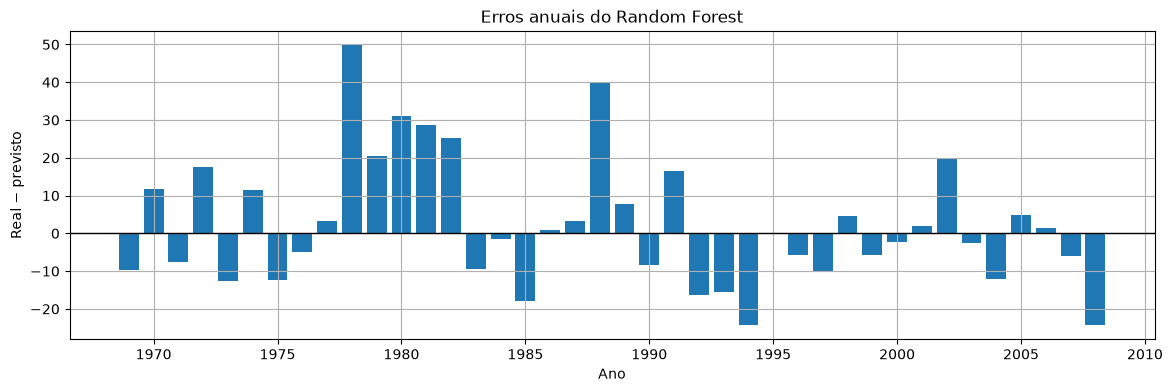

,real,previsao_rf,erro,erro_absoluto
ano,,,,
1978,92.5,42.63,49.87,49.87
1988,100.2,60.53,39.67,39.67
1980,154.6,123.44,31.16,31.16
1981,140.4,111.74,28.66,28.66
1982,115.9,90.68,25.22,25.22
1994,29.9,54.15,-24.25,24.25
2008,2.9,27.09,-24.19,24.19
1979,155.4,134.92,20.48,20.48
2002,104.0,84.36,19.64,19.64


In [10]:
resultado_rf["erro"] = resultado_rf["real"] - resultado_rf["previsao_rf"]
resultado_rf["erro_absoluto"] = resultado_rf["erro"].abs()

fig, ax = plt.subplots(figsize=(14, 4))
ax.axhline(0, color="black", linewidth=1)
ax.bar(resultado_rf.index, resultado_rf["erro"])
ax.set(title="Erros anuais do Random Forest", xlabel="Ano", ylabel="Real − previsto")
plt.show()

display(resultado_rf.sort_values("erro_absoluto", ascending=False).head(10).round(2))

## 9. Importância das variáveis (defasagens)

O Random Forest permite estimar a importância relativa de cada coluna para as divisões das árvores. Essas importâncias são úteis como descrição do modelo, mas **não demonstram causalidade** e podem distribuir importância entre variáveis correlacionadas.

Para manter a comparação coerente, ajustamos o modelo final ao conjunto de treinamento e inspecionamos a importância das defasagens.

,importancia
t-1,0.6458
t-9,0.0769
t-8,0.0745
t-7,0.0460
t-10,0.0352
t-4,0.0287
t-2,0.0196
t-3,0.0189
t-5,0.0153
t-6,0.0146


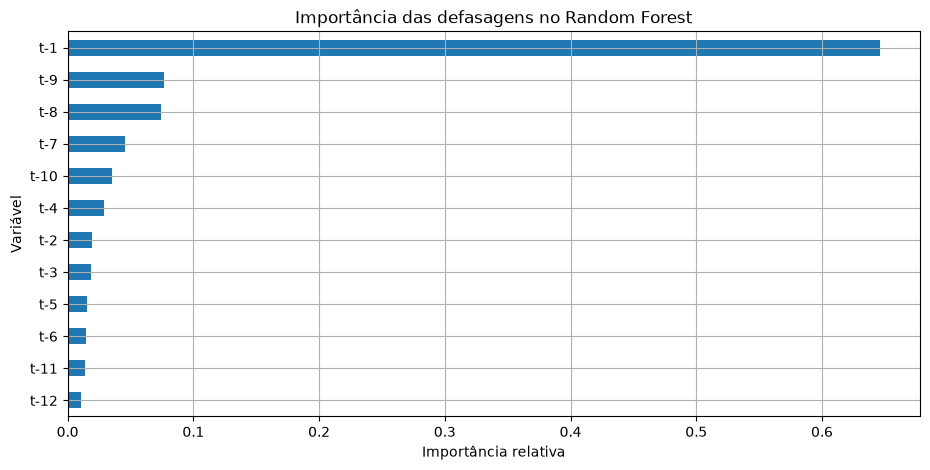

In [11]:
modelo_rf_treino = RandomForestRegressor(
    n_estimators=200,
    random_state=SEMENTE,
    n_jobs=-1,
    **melhores_parametros
)
modelo_rf_treino.fit(X_treino, y_treino)

importancias = pd.Series(
    modelo_rf_treino.feature_importances_,
    index=X_treino.columns,
    name="importancia"
).sort_values(ascending=False)

display(importancias.to_frame().round(4))

fig, ax = plt.subplots(figsize=(11, 5))
importancias.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Importância das defasagens no Random Forest", xlabel="Importância relativa", ylabel="Variável")
plt.show()

## 10. Comparação opcional com o ARIMA do Notebook 03

Para comparar os modelos diretamente, o ideal é usar as previsões exportadas no Notebook 03. Este bloco procura `sunspots_previsoes_arima.csv` na pasta de trabalho. Se o arquivo não estiver presente, a comparação é simplesmente ignorada; execute o Notebook 03 e mantenha o CSV na mesma pasta para habilitá-la.

A comparação só é válida se ambos os arquivos cobrirem exatamente os mesmos anos de teste.

,MAE,RMSE,MAPE (%),Pontos no MAPE,R²
Random Forest,12.726,16.795,45.76,40.0,0.879
ARIMA,14.972,18.257,58.06,40.0,0.858


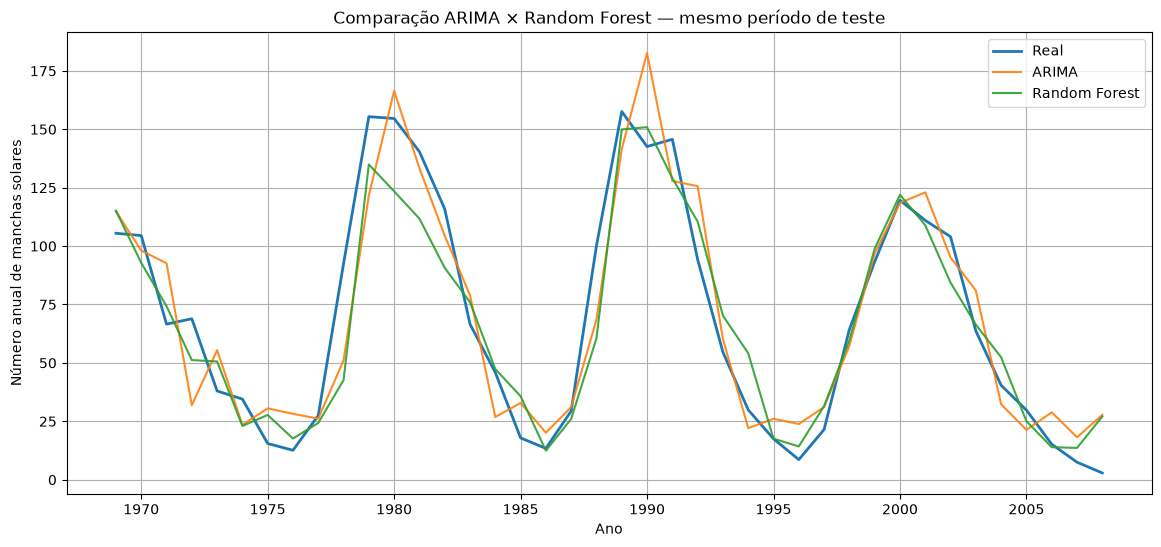

In [12]:
caminho_arima = Path("sunspots_previsoes_arima.csv")

if caminho_arima.exists():
    previsoes_arima = pd.read_csv(caminho_arima, index_col="ano")
    previsoes_arima.index = previsoes_arima.index.astype(int)

    if not {"real", "previsao_arima"}.issubset(previsoes_arima.columns):
        print("O CSV do ARIMA não contém as colunas esperadas. Verifique a saída do Notebook 03.")
    else:
        comparacao = resultado_rf[["real", "previsao_rf"]].join(
            previsoes_arima[["real", "previsao_arima"]].drop(columns="real"),
            how="inner"
        )
        if len(comparacao) != len(resultado_rf) or not np.array_equal(comparacao.index.to_numpy(), resultado_rf.index.to_numpy()):
            print("Os anos do CSV ARIMA não coincidem integralmente com o período de teste do Random Forest.")
        else:
            metricas_comparacao = pd.DataFrame({
                "Random Forest": calcular_metricas(comparacao["real"], comparacao["previsao_rf"]),
                "ARIMA": calcular_metricas(comparacao["real"], comparacao["previsao_arima"]),
            }).T
            display(metricas_comparacao.round(3))

            fig, ax = plt.subplots(figsize=(14, 6))
            ax.plot(comparacao.index, comparacao["real"], label="Real", linewidth=2)
            ax.plot(comparacao.index, comparacao["previsao_arima"], label="ARIMA", alpha=0.9)
            ax.plot(comparacao.index, comparacao["previsao_rf"], label="Random Forest", alpha=0.9)
            ax.set(title="Comparação ARIMA × Random Forest — mesmo período de teste", xlabel="Ano", ylabel="Número anual de manchas solares")
            ax.legend()
            plt.show()
else:
    print("CSV do ARIMA não encontrado. Execute o Notebook 03 e coloque sunspots_previsoes_arima.csv nesta pasta para comparar os modelos.")

## 11. Exportação dos resultados

Os arquivos CSV permitem reutilizar as tabelas no relatório e na apresentação. Eles serão gravados na pasta em que o Jupyter estiver sendo executado.

In [13]:
resultado_rf.to_csv("sunspots_previsoes_random_forest.csv")
metricas_rf.to_csv("sunspots_metricas_random_forest.csv")
tabela_busca_rf.to_csv("sunspots_busca_random_forest.csv", index=False)
importancias.to_csv("sunspots_importancia_lags_random_forest.csv", header=True)

print("Arquivos exportados:")
print("- sunspots_previsoes_random_forest.csv")
print("- sunspots_metricas_random_forest.csv")
print("- sunspots_busca_random_forest.csv")
print("- sunspots_importancia_lags_random_forest.csv")

Arquivos exportados:
- sunspots_previsoes_random_forest.csv
- sunspots_metricas_random_forest.csv
- sunspots_busca_random_forest.csv
- sunspots_importancia_lags_random_forest.csv


## 12. Como interpretar e apresentar os resultados

Antes de concluir que o Random Forest é melhor ou pior que o ARIMA, respondam:

1. O modelo acompanha a periodicidade aproximada de 11 anos ou tende a produzir previsões mais suaves?
2. Ele consegue antecipar os picos, ou reage com atraso às mudanças rápidas?
3. Em quais anos os erros absolutos são maiores? Esses anos correspondem a picos, vales ou transições?
4. Quais defasagens receberam maior importância? Isso é compatível com o comportamento cíclico observado? Lembrem-se de que importância não é causalidade.
5. O desempenho muda quando comparamos MAE, RMSE, MAPE e R²? Por que não devemos escolher um modelo por uma única métrica?
6. A validação temporal foi separada do teste final? O notebook evita usar valores futuros na previsão?

### Limitações que devem aparecer no relatório

- O Random Forest não modela explicitamente uma estrutura temporal ou uma periodicidade; ele aprende relações entre as defasagens fornecidas.
- Foram usadas 12 defasagens, uma escolha motivada pelo ciclo solar aproximado, mas isso não garante que sejam suficientes ou ideais.
- A importância das variáveis é descritiva, não causal.
- Resultados de um único período de teste dependem dos anos escolhidos; outras divisões temporais podem produzir métricas diferentes.
- O MAPE deve ser interpretado com cautela quando a série se aproxima de zero.

### Conclusão provisória

O Random Forest é um segundo método, de natureza diferente do ARIMA. A conclusão do projeto deve se apoiar na comparação das previsões e dos erros no mesmo período, além da análise dos gráficos e das limitações de cada abordagem.